# Week 11 Lab Work

**Dataset:** Adult / Census Income (UCI Machine Learning Repository)

1. Load the same pre-processed dataset as the last lab works.
2. Scale the features and take a fixed random sample.
3. Build the pairwise Euclidean distance matrix.
4. Write Single, Complete and Average linkage by hand and check them against SciPy.
5. Draw a dendrogram for each method.
6. Cut each tree into 2 clusters and compare them with `income`.
7. Plot the clusters on a 2D PCA view.


In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

cols = ["age", "workclass", "fnlwgt", "education", "education-num",
        "marital-status", "occupation", "relationship", "race", "sex",
        "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]


def get_file(data_filename):
    for base in [".", ".."]:
        if not os.path.isdir(base):
            continue
        for root, dirs, files in os.walk(base):
            if data_filename in files:
                return os.path.join(root, data_filename)

    print(f"'{data_filename}' not found in the workspace. Downloading it dynamically...")
    url = f"https://archive.ics.uci.edu/ml/machine-learning-databases/adult/{data_filename}"
    urllib.request.urlretrieve(url, data_filename)
    return data_filename


# 1. Load and pre-process the data
path = get_file("adult.data")
print(f"Loading data from: {path}")
df = pd.read_csv(path, header=None, names=cols, skipinitialspace=True, na_values="?")
df = df.dropna().drop_duplicates().reset_index(drop=True)
df["income"] = (df["income"] == ">50K").astype(int)
df = pd.get_dummies(df, drop_first=True)

print("Shape:", df.shape)
print("Missing cells:", df.isnull().sum().sum())
df.head()


'adult.data' not found in the workspace. Downloading it dynamically...


Loading data from: adult.data
Shape: (30139, 97)
Missing cells: 0


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,income,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,77516,13,2174,0,40,0,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,50,83311,13,0,0,13,0,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,38,215646,9,0,0,40,0,False,True,False,...,False,False,False,False,False,False,False,True,False,False
3,53,234721,7,0,0,40,0,False,True,False,...,False,False,False,False,False,False,False,True,False,False
4,28,338409,13,0,0,40,0,False,True,False,...,False,False,False,False,False,False,False,False,False,False


## 2. Scale the features and sample the rows

`MinMaxScaler` is used instead of `StandardScaler` because a rare one-hot column would otherwise be scaled to a huge value and turn one row into an outlier for every method; with `MinMaxScaler` the one-hot columns stay 0 or 1 and the numeric columns go to 0-1.

Hierarchical linkage needs a full pairwise distance matrix. For about 30,000 rows this is several GB and will hang, so a fixed random sample of 2000 rows (`random_state=42`) is used. `income` is kept out of the features and is used only to check the clusters.

In [2]:
sample = df.sample(n=2000, random_state=42)
X = MinMaxScaler().fit_transform(sample.drop(columns=["income"]))
y = sample["income"].to_numpy()
print("Sample shape:", X.shape)
print("Income share in sample:", y.mean().round(4))


Sample shape: (2000, 96)
Income share in sample: 0.253


## 3. Pairwise distance matrix

Every linkage method starts from the Euclidean distance between each pair of rows.

In [3]:
D = squareform(pdist(X, metric="euclidean"))
print("Distance matrix shape:", D.shape)

Distance matrix shape: (2000, 2000)


## 4. Linkage from scratch

The function starts with every row as its own cluster. At each step it merges the two closest clusters and rewrites the distance row of the new cluster with the Lance-Williams rule:

- **Single:** the smaller of the two old distances.
- **Complete:** the larger of the two old distances.
- **Average:** the mean of the two old distances, weighted by cluster size.

It returns a linkage matrix `Z` in the same format as SciPy: columns are the two merged ids, the merge height and the new cluster size.

In [4]:
def agglomerative(D, method):
    n = len(D)
    W = D.astype(float).copy()
    np.fill_diagonal(W, np.inf)
    label = np.arange(n)
    size = np.ones(n)
    Z = np.zeros((n - 1, 4))
    for step in range(n - 1):
        i, j = np.unravel_index(np.argmin(W), W.shape)
        h = W[i, j]
        if method == "single":
            row = np.minimum(W[i], W[j])
        elif method == "complete":
            row = np.maximum(W[i], W[j])
        else:
            row = (size[i] * W[i] + size[j] * W[j]) / (size[i] + size[j])
        W[i, :] = row
        W[:, i] = row
        W[i, i] = np.inf
        W[j, :] = np.inf
        W[:, j] = np.inf
        Z[step] = [min(label[i], label[j]), max(label[i], label[j]), h, size[i] + size[j]]
        label[i] = n + step
        size[i] += size[j]
    return Z


## 5. Run the three methods and check them against SciPy

The merge heights of our own `Z` must equal the heights from `scipy.cluster.hierarchy.linkage`.

In [5]:
import time

methods = ["single", "complete", "average"]
trees = {}
for m in methods:
    t0 = time.time()
    trees[m] = agglomerative(D, m)
    ref = linkage(X, method=m, metric="euclidean")
    print(f"{m:>8}: {time.time() - t0:5.1f} s, heights match SciPy = {np.allclose(trees[m][:, 2], ref[:, 2])}")


  single:   1.7 s, heights match SciPy = True


complete:   1.9 s, heights match SciPy = True


 average:   1.7 s, heights match SciPy = True


## 6. Dendrograms

With 2000 leaves a full dendrogram is unreadable, so each tree is truncated to its last 20 merges.

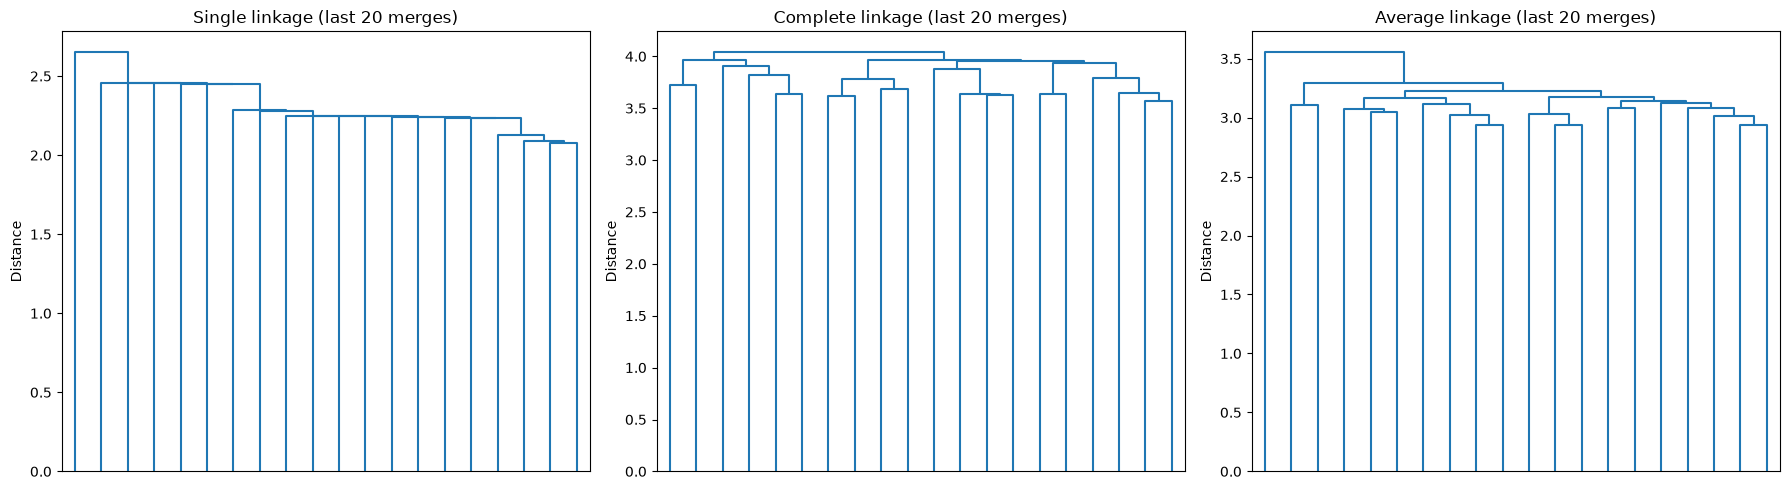

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, m in zip(axes, methods):
    dendrogram(trees[m], truncate_mode="lastp", p=20, ax=ax, no_labels=True)
    ax.set_title(f"{m.capitalize()} linkage (last 20 merges)")
    ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()


## 7. Cut into 2 clusters and compare

Each tree is cut into 2 clusters. The clusters are compared with `income` by a cross-tab and the Adjusted Rand Index (ARI; 0 means no better than chance), and by the silhouette score.

In [7]:
k = 2
results = []
for m in methods:
    labels = fcluster(trees[m], t=k, criterion="maxclust")
    results.append({"Linkage": m.capitalize(),
                    "Cluster sizes": np.bincount(labels)[1:].tolist(),
                    "ARI vs income": round(adjusted_rand_score(y, labels), 4),
                    "Silhouette": round(silhouette_score(X, labels), 4)})
    print(f"\n{m.capitalize()} linkage")
    print(pd.crosstab(labels, y, rownames=["cluster"], colnames=["income"]))
print()
print(pd.DataFrame(results).to_string(index=False))



Single linkage


income      0    1
cluster           
1        1493  506
2           1    0

Complete linkage
income      0    1
cluster           
1         172   75
2        1322  431

Average linkage
income      0    1
cluster           
1        1493  506
2           1    0

 Linkage Cluster sizes  ARI vs income  Silhouette
  Single     [1999, 1]        -0.0007      0.2425
Complete   [247, 1753]         0.0221      0.0671
 Average     [1999, 1]        -0.0007      0.2425


The same trees are cut again into 5 clusters to see how the methods differ.

In [8]:
for m in methods:
    labels = fcluster(trees[m], t=5, criterion="maxclust")
    print(f"{m.capitalize():>8}:", sorted(np.bincount(labels)[1:].tolist(), reverse=True))

  Single: [1996, 1, 1, 1, 1]
Complete: [985, 446, 322, 142, 105]
 Average: [1941, 47, 6, 5, 1]


## 8. PCA view of the clusters

The 2D PCA view shows the same 2-cluster cuts.

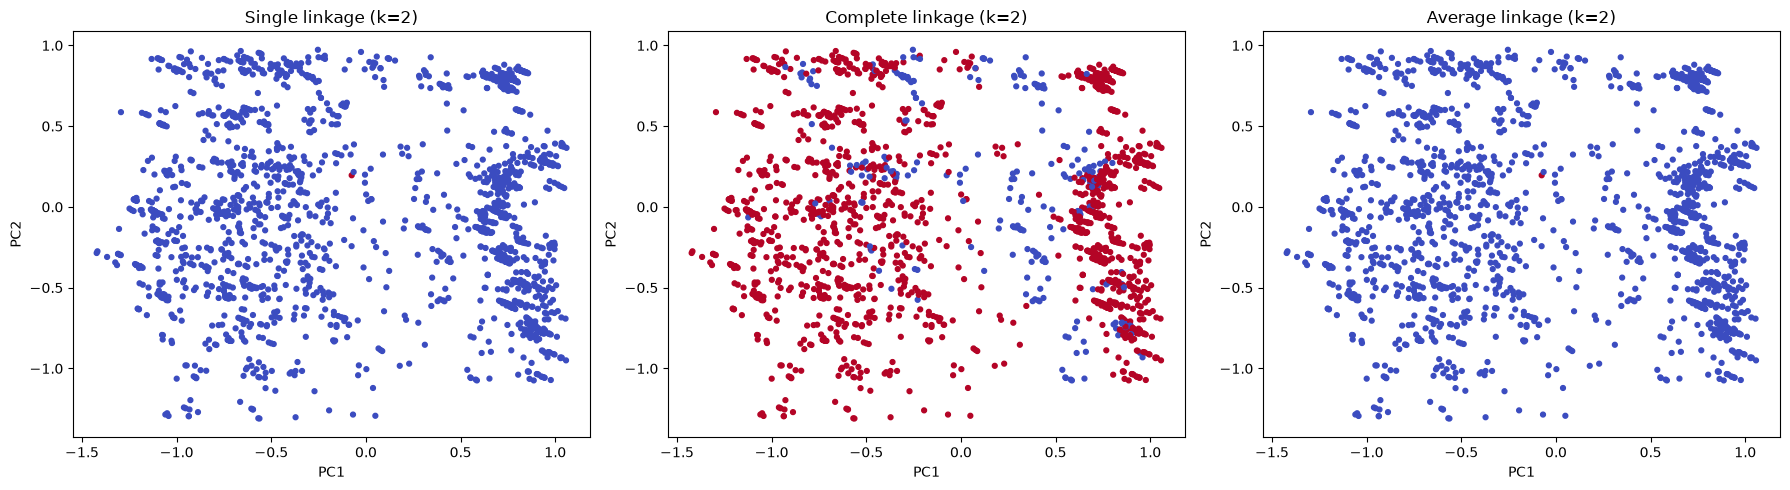

In [9]:
pcs = PCA(n_components=2).fit_transform(X)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, m in zip(axes, methods):
    ax.scatter(pcs[:, 0], pcs[:, 1], c=fcluster(trees[m], t=k, criterion="maxclust"), cmap="coolwarm", s=12)
    ax.set_title(f"{m.capitalize()} linkage (k={k})")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()


## 9. Conclusions

| Method | Cluster sizes (k=2) | ARI vs income | Silhouette | Cluster sizes (k=5) |
|---|---|---|---|---|
| Single | [1999, 1] | -0.0007 | 0.2425 | [1996, 1, 1, 1, 1] |
| Complete | [247, 1753] | 0.0221 | 0.0671 | [985, 446, 322, 142, 105] |
| Average | [1999, 1] | -0.0007 | 0.2425 | [1941, 47, 6, 5, 1] |

- Our own linkage code gives the same merge heights as SciPy for all three methods.
- **Single linkage** chains. At k=2 it cuts off one lone point (1999 and 1 rows), and at k=5 it gives [1996, 1, 1, 1, 1]. Average linkage does the same at k=2 and finds only a few small groups at k=5 ([1941, 47, 6, 5, 1]).
- **Complete linkage** gives the most balanced clusters: [247, 1753] at k=2 and [985, 446, 322, 142, 105] at k=5. Its silhouette (0.0671) is the lowest, but it is the only method that splits the data into real groups.
- No method finds `income`. The ARI is -0.0007 for Single and Average and 0.0221 for Complete, all near 0. The higher silhouette of Single and Average (0.2425) only comes from cutting off one outlier.
